# [통계적 검정과 인과추론] 종합 과제 - A/B 테스트 

- 데이터셋: Fast Food Marketing Campaign A/B 테스트 데이터셋
- 데이터셋 링크: https://www.kaggle.com/datasets/chebotinaa/fast-food-marketing-campaign-ab-test 
- 다운로드 일시: 2026-11-06
- 목표: 세 프로모션 중 신메뉴 매출에 차이를 만드는 것이 있는지 검정하고 의사결정 제안
- 도메인: 마케팅, 푸드
- 특징: 다양한 지점 및 프로모션별 분석 가능


 ## 1단계. 데이터셋 점검

--- 

### 1) 라이브러리와 데이터 불러오기

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

np.random.seed(42)   # 재현성: 나중에 난수를 쓸 때 항상 같은 결과가 나오게 고정

df = pd.read_csv("WA_Marketing-Campaign.csv")
df.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


> - 관측 단위는 매장×주차이며, 결과 변수는 주간 신메뉴 매출(`SalesInThousands`)이다.
> - 매장마다 하나의 프로모션이 4주 내내 고정 배정되어 있다.
> - 같은 매장이 반복 측정되므로 행을 독립 표본으로 볼 수 없다. 매장별 평균으로 집계해 분석할 필요가 있다.

### 2)기본 확인


In [2]:
print("행, 열:", df.shape)   # 548행이 맞는지
df.info()                     # 자료형 확인 (Promotion이 숫자형인지)
print(df.isna().sum())        # 열별 결측치 개수

n_raw = len(df)               # 정제 전 행 수 저장 (나중에 전후 비교용)

행, 열: (548, 7)
<class 'pandas.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    str    
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), str(1)
memory usage: 33.1 KB
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
SalesInThousands    0
dtype: int64


- 데이터는 548행 × 7열이다.
- 모든 컬럼의 Non-Null이 548개이고 결측치 합계도 0이므로 결측치는 없다.
- 타입은 정수형 5개, 실수형 1개(SalesInThousands), 문자열 1개(MarketSize)이다.
- 548행 = 137개 매장 × 4주로 추정된다. LocationID 고유값 수로 확인이 필요하다.

In [3]:
df.groupby('LocationID').size().value_counts()

4    137
Name: count, dtype: int64

### 3)중복확인

In [4]:
# 모든 값이 똑같은 행
print("완전 중복 행:", df.duplicated().sum())

# 같은 매장의 같은 주차가 두 번 기록됐는지
print("매장-주차 중복:", df.duplicated(subset=['LocationID', 'week']).sum())


완전 중복 행: 0
매장-주차 중복: 0


- 137개 매장 중 1개 매장은 3주차만 기록되어 있고, 2개 매장은 2주차만 기록되어 있음. 따라서 이 3개 매장은 제거해야 함.

### 4)배정 일관성

In [5]:
# 한 매장에 프로모션이 하나만 배정됐는지
promo_per_loc = df.groupby('LocationID')['Promotion'].nunique()
print("프로모션이 2개 이상인 매장:", (promo_per_loc > 1).sum())

# 매장 고정 특성이 주차마다 바뀌지 않는지 (입력 오류 점검)
print("MarketSize 불일치:", (df.groupby('LocationID')['MarketSize'].nunique() > 1).sum())
print("AgeOfStore 불일치:", (df.groupby('LocationID')['AgeOfStore'].nunique() > 1).sum())

프로모션이 2개 이상인 매장: 0
MarketSize 불일치: 0
AgeOfStore 불일치: 0


- 프로모션은 마켓별 1가지만 적용되었다.

### 5)매장 단위로 집계

In [6]:
# 배정 단위 = 매장 → 분석 단위도 매장
# 같은 매장의 4주 매출은 서로 독립이 아니므로 평균 내서 매장당 1개 값으로 만든다
loc = (df.groupby(['LocationID', 'Promotion', 'MarketSize', 'AgeOfStore'], as_index=False)
         ['SalesInThousands'].mean()
         .rename(columns={'SalesInThousands': 'avg_weekly_sales'}))

loc['Promotion'] = loc['Promotion'].astype('category')   # 숫자가 아니라 이름표로 취급

print("정제 전 행 수:", n_raw, "→ 분석 단위(매장) 수:", len(loc))

정제 전 행 수: 548 → 분석 단위(매장) 수: 137


### 6)SRM점검

In [7]:
# 매장 수 기준으로 세 그룹이 고르게 나뉘었는지 (균등 배정 가정)
counts = loc['Promotion'].value_counts().sort_index()
print(counts)

expected = [len(loc) / 3] * 3
print(stats.chisquare(counts.values, expected))   # p가 커야 정상

Promotion
1    43
2    47
3    47
Name: count, dtype: int64
Power_divergenceResult(statistic=np.float64(0.23357664233576644), pvalue=np.float64(0.8897735194498095))


### 7)시장 규모 균형 확인

In [8]:
# 배정 전 특성(시장 규모)이 세 그룹에 고르게 섞였는지
# 결과(매출)가 아니므로 지금 봐도 괜찮다
pd.crosstab(loc['Promotion'], loc['MarketSize'])

MarketSize,Large,Medium,Small
Promotion,,,
1,14,24,5
2,16,27,4
3,12,29,6


## ***1단계 데이터 점검 결과***
- 기본 확인: 행 수(548), 칼럼(7), 결측치(0), Promotion값 숫자형 -> 범주형
- 중복: 완전 중복 0건, 매장-주차 중복 0건, 모든 매장이 4주 데이터 보유
- 배정 일관성: 프로모션 배정에 일관성이 있다.
- 분석 단위: 548행 → 137개 매장 (이유: 4주차별 137개 매장에 적용)
- SRM: χ² = 0.23357664233576644, p = 0.8897735194498095 → 해석: 균등 배정 가정에 어긋난 증거가 없고, 배정에 문제가 있다고 볼 이유가 없다.
- 시장 규모 균형: 프로모션별 매장크기가 고르게 분포됨

## 2단계 질문과 가설

---

- 목표: 햄버거 체인 마케팅팀이 신메뉴 전국 출시 때 사용할 프로모션을 결정할 수 있도록,
  세 프로모션 중 신메뉴 매출을 가장 높이는 것이 무엇인지, 그 차이가 분명한지 알아본다.

### 1)질문과 가설
- 질문: 세 프로모션 간 매장당 평균 주간 신메뉴 매출에 차이가 있는가?
- H₀: 세 프로모션의 매장당 평균 주간 신메뉴 매출은 모두 같다
- H₁: 적어도 한 프로모션의 매장당 평균 주간 신메뉴 매출은 다르다

### 2)참고 사항
- 분석 단위: 매장(137개), 지표: 매장별 4주 평균 주간 매출
- 유의수준: α = 0.05
- 주 검정: 일원 ANOVA → 유의하면 Tukey HSD
- 대안: 정규성이 크게 깨지면 Kruskal-Wallis / 등분산만 깨지면 Welch ANOVA
- 의사결정 규칙:
  - 최고 프로모션이 나머지 두 개 모두보다 유의하게 높음 → 출시
  - 한 개보다만 유의하게 높음 → 두 후보를 놓고 추가 수집
  - ANOVA가 유의하지 않음 → 보류 또는 추가 수집 (MDE와 함께 판단)

## 3단계: 검정 고르기

---

### 1) 표본크기, 평균, 표준편차

In [9]:
import matplotlib.pyplot as plt

promos = sorted(loc['Promotion'].unique())
groups = [loc.loc[loc['Promotion'] == p, 'avg_weekly_sales'].values for p in promos]

for p, g in zip(promos, groups):
    print(f"프로모션 {p}: n={len(g)}, 평균={g.mean():.2f}, 표준편차={g.std(ddof=1):.2f}")

프로모션 1: n=43, 평균=58.10, 표준편차=16.03
프로모션 2: n=47, 평균=47.33, 표준편차=14.50
프로모션 3: n=47, 평균=55.36, 표준편차=16.38


### 2) 히스토그램, Q-Q plot

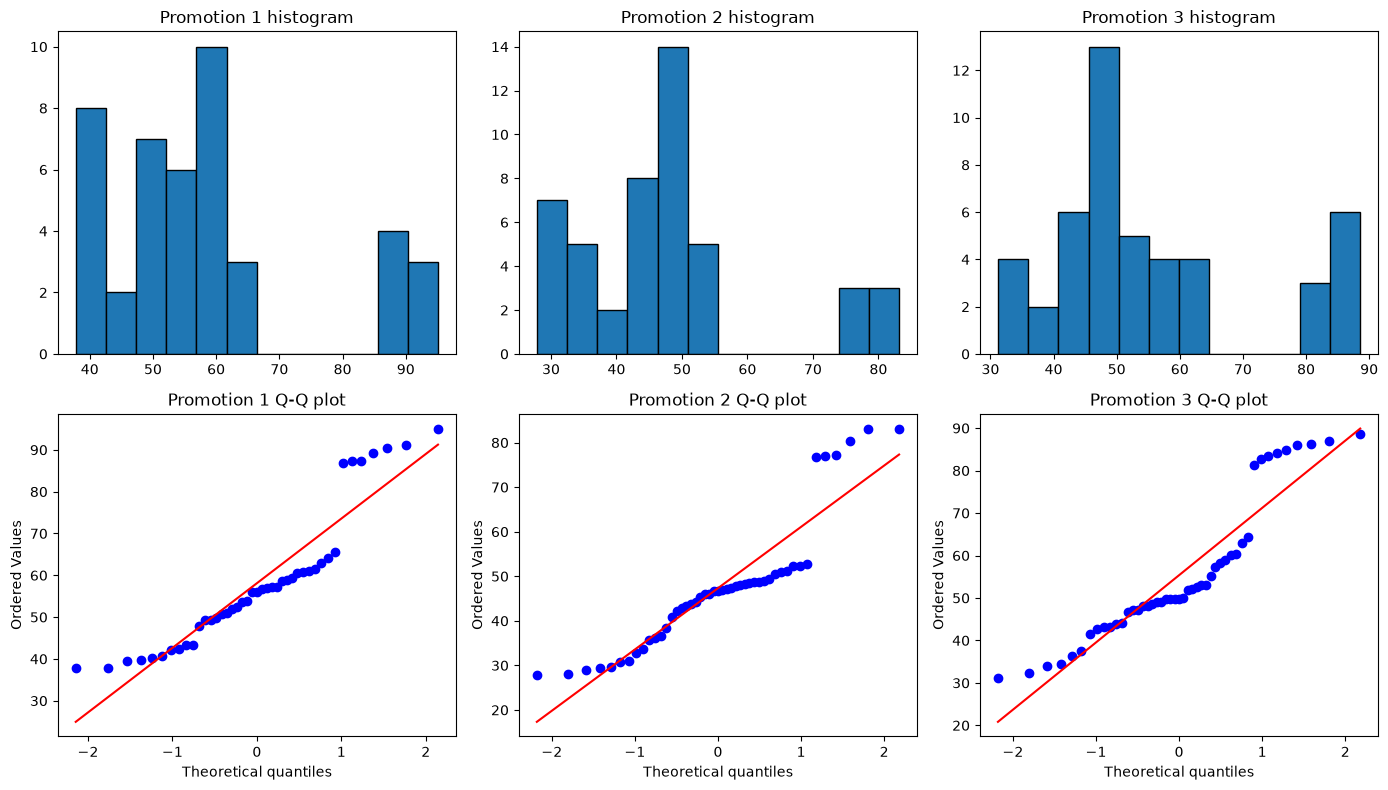

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, (p, g) in enumerate(zip(promos, groups)):
    axes[0, i].hist(g, bins=12, edgecolor='black')
    axes[0, i].set_title(f'Promotion {p} histogram')
    stats.probplot(g, dist='norm', plot=axes[1, i])
    axes[1, i].set_title(f'Promotion {p} Q-Q plot')

plt.tight_layout()
plt.show()

- 정규분포

### 3)Shapiro-Wilk 정규성 검정

In [11]:
for p, g in zip(promos, groups):
    w, pval = stats.shapiro(g)
    print(f"프로모션 {p}: W={w:.3f}, p={pval:.4f}")

프로모션 1: W=0.868, p=0.0002
프로모션 2: W=0.849, p=0.0000
프로모션 3: W=0.876, p=0.0001


- p < 0.05 정규분포라고 보기 어렵다.

### 4)Levene 등분산 검정

In [12]:
stat, pval = stats.levene(*groups, center='median')
print(f"Levene: W={stat:.3f}, p={pval:.4f}")

Levene: W=0.468, p=0.6272


- 중앙값으로 표준편차를 구함 (극단값에 끌려가는 것을 막기위해)
- H0: 세 그룹의 분산이 같다

## 3단계 검정 선택
- 정규성(그래프): 세 그룹 모두 히스토그램이 대체로 봉우리 하나의 대칭에 가까운 모양이고, Q-Q plot은 점들은 가운데는 직선 위에 있고 양 끝 일부만 벗어난다.
- 정규성(Shapiro-Wilk): 프로모션 1 p=0.0002, 2 p=0.0000, 3 p=0.0001 → 3개 그룹에서 정규성 기각
- 등분산(Levene):W=0.468, p=0.6272 → 등분산 가정을 기각할 증거 없음
  표준편차 최대/최소 비율 = ( )

나는 일원 ANOVA를 선택했다. 성공 지표인 매장당 평균 주간 신메뉴 매출은 연속형이고,
비교할 프로모션은 3개다. 같은 매장의 주차별 매출은 서로 독립이 아니므로 매장 단위로
묶어 독립성을 확보했다. Shapiro-Wilk에서 정규성이 기각되었지만, 그래프상 벗어남이
심하지 않고, 그룹당 표본이 43~47개로 충분하며 그룹 크기가 비슷해 ANOVA는 이 정도의
정규성 위반에 강하다. 등분산 가정은 기각되지 않았으므로 Welch ANOVA 대신 일반 ANOVA를 쓴다.
정규성 위반의 영향을 확인하기 위해 Kruskal-Wallis를 민감도 분석으로 함께 수행하고,
두 결과가 같은 결론인지 보고한다.

In [13]:
for p, g in zip(promos, groups):
    print(f"프로모션 {p}: 왜도 = {stats.skew(g):.2f}, 첨도 = {stats.kurtosis(g):.2f}")

프로모션 1: 왜도 = 0.97, 첨도 = 0.06
프로모션 2: 왜도 = 1.11, 첨도 = 0.85
프로모션 3: 왜도 = 0.82, 첨도 = -0.37


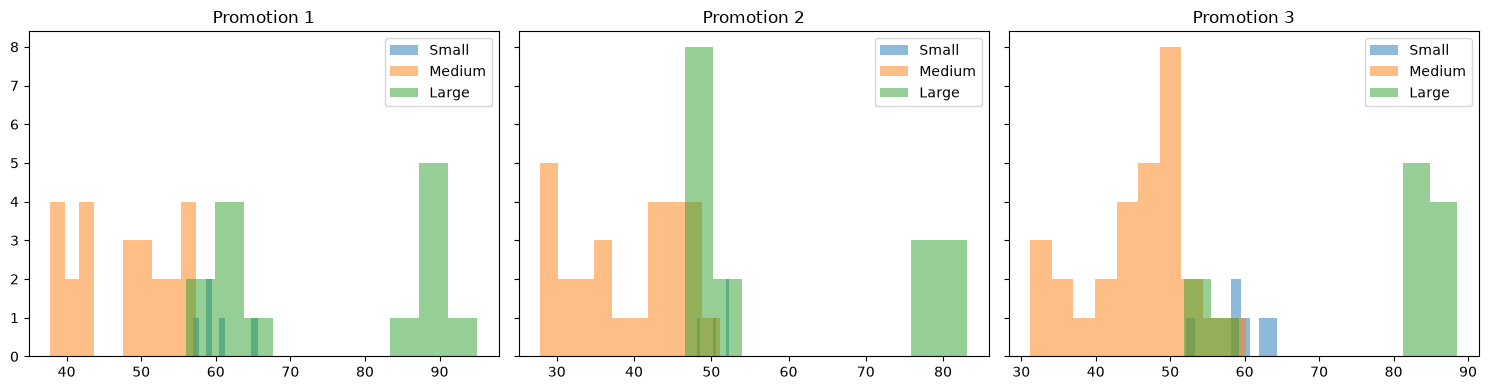

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for i, p in enumerate(promos):
    sub = loc[loc['Promotion'] == p]
    for ms in ['Small', 'Medium', 'Large']:
        axes[i].hist(sub.loc[sub['MarketSize'] == ms, 'avg_weekly_sales'],
                     bins=10, alpha=0.5, label=ms)
    axes[i].set_title(f'Promotion {p}')
    axes[i].legend()

plt.tight_layout()
plt.show()

Shapiro-Wilk에서 세 그룹 모두 정규성이 강하게 기각되었으나(p < 0.001), 
왜도 ( ~ ), 첨도 ( ~ )로 극단적인 비대칭은 없었고, 
시장 규모별로 보면 (관찰 내용). 
또한 의사결정에 필요한 것은 총매출과 직결되는 평균 매출의 비교이므로 
평균을 검정하는 ANOVA를 주 검정으로 유지한다.

In [15]:
sds = [g.std(ddof=1) for g in groups]
print(f"최대/최소 비율 = {max(sds) / min(sds):.2f}")

최대/최소 비율 = 1.13


## 3단계 검정 선택
- 정규성(그래프): 세 그룹 모두 봉우리 하나에 오른쪽 꼬리가 약간 긴 모양.
  Q-Q plot은 가운데는 직선 위에 있고 오른쪽 위 끝이 직선에서 벗어남.
- 정규성(Shapiro-Wilk): 프로모션 1 p=0.0002, 2 p<0.0001, 3 p=0.0001 → 세 그룹 모두 기각
- 왜도/첨도: 왜도 0.82~1.11(중간 정도의 오른쪽 치우침), 첨도 -0.37~0.85(꼬리 두께 정상 범위)
- 시장 규모별 분포: Large 시장 매장들이 매출이 높은 쪽에 따로 모여 오른쪽 꼬리를 만듦.
  이 모양은 세 프로모션 모두에서 비슷함
- 등분산(Levene): W=0.468, p=0.627 → 기각할 증거 없음. 표준편차 최대/최소 비율 = 1.13

나는 일원 ANOVA를 선택했다. 성공 지표인 매장당 평균 주간 신메뉴 매출은 연속형이고,
비교할 프로모션은 3개다. 같은 매장의 주차별 매출은 서로 독립이 아니므로 매장 단위로
묶어 독립성을 확보했다. Shapiro-Wilk에서 세 그룹 모두 정규성이 기각되었지만, 원인은
중간 정도의 오른쪽 치우침(왜도 약 1)이며 극단적 비대칭이나 두꺼운 꼬리는 없었다.
시장 규모별로 보면 이 치우침은 매출 수준이 높은 Large 시장 매장들이 섞여 생긴 것으로,
이상한 값이 아니라 매장들의 실제 다양성을 반영한다. 그룹당 표본이 43~47개로 충분하고
그룹 크기가 비슷하며, 등분산 가정도 기각되지 않아(표준편차 비율 1.13), ANOVA는 이 정도의
정규성 위반에 강하다. 또한 의사결정에 필요한 것은 총매출과 직결되는 평균 매출의 비교이므로
평균을 검정하는 ANOVA를 주 검정으로 한다. 정규성 위반의 영향을 확인하기 위해
Kruskal-Wallis를 민감도 분석으로 함께 수행하고, 두 결과가 같은 결론인지 보고한다.

## 4단계

In [16]:
f_stat, p_anova = stats.f_oneway(*groups)

all_vals = np.concatenate(groups)
grand_mean = all_vals.mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((all_vals - grand_mean) ** 2).sum()
eta2 = ss_between / ss_total

df_between = len(groups) - 1
df_within = len(all_vals) - len(groups)
print(f"F({df_between}, {df_within}) = {f_stat:.2f}, p = {p_anova:.4g}, η² = {eta2:.3f}")

F(2, 134) = 5.85, p = 0.003681, η² = 0.080


In [17]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(endog=loc['avg_weekly_sales'],
                          groups=loc['Promotion'].astype(str),
                          alpha=0.05)
print(tukey.summary())

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2 -10.7696  0.004 -18.5951  -2.944   True
     1      3  -2.7345 0.6862 -10.5601   5.091  False
     2      3   8.0351 0.0371   0.3854 15.6847   True
-----------------------------------------------------


In [18]:
from itertools import combinations

def cohens_d(a, b):
    na, nb = len(a), len(b)
    pooled_sd = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / pooled_sd

for (i, a), (j, b) in combinations(enumerate(groups), 2):
    diff = a.mean() - b.mean()
    rel = diff / b.mean() * 100
    print(f"P{promos[i]} - P{promos[j]}: 절대 차이 = {diff:.2f}, "
          f"상대 차이 = {rel:+.1f}% (P{promos[j]} 기준), d = {cohens_d(a, b):.2f}")

P1 - P2: 절대 차이 = 10.77, 상대 차이 = +22.8% (P2 기준), d = 0.71
P1 - P3: 절대 차이 = 2.73, 상대 차이 = +4.9% (P3 기준), d = 0.17
P2 - P3: 절대 차이 = -8.04, 상대 차이 = -14.5% (P3 기준), d = -0.52


In [19]:
h_stat, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {h_stat:.2f}, p = {p_kw:.4g}")

Kruskal-Wallis: H = 17.33, p = 0.0001727


## 4단계 결과
- 그룹 평균(매장당 평균 주간 신메뉴 매출): 
  프로모션 1 = 58.10 (n=43), 프로모션 2 = 47.33 (n=47), 프로모션 3 = 55.36 (n=47)
- ANOVA: F(2, 134) = 5.85, p = .004, η² = 0.080 (중간 효과)
- Tukey HSD (95% 동시 신뢰구간):
  - 1 vs 2: 1이 10.77 높음, 95% CI [2.94, 18.60], p-adj = .004, d = 0.71, 상대 +22.8%
  - 3 vs 2: 3이 8.04 높음, 95% CI [0.39, 15.68], p-adj = .037, d = 0.52, 상대 +17.0%
  - 1 vs 3: 1이 2.73 높음, 95% CI [-5.09, 10.56], p-adj = .686, d = 0.17, 상대 +4.9%
- 민감도 분석: Kruskal-Wallis H = 17.33, p < .001 → ANOVA와 결론 일치

보고 문장:
프로모션 1과 3의 매장당 평균 주간 신메뉴 매출이 프로모션 2보다 높았다
(58.10, 55.36 vs 47.33; F(2, 134) = 5.85, p = .004, η² = 0.08).
프로모션 1은 2보다 10.77(+22.8%, d = 0.71), 프로모션 3은 2보다 8.04(+17.0%, d = 0.52)
높았으나, 프로모션 1과 3의 차이(2.73, +4.9%, d = 0.17)는 유의하지 않았다
(95% CI [-5.09, 10.56]).

## 5단계 A(MDE)

In [20]:
from statsmodels.stats.power import TTestIndPower

a = groups[promos.index(1)]   # 프로모션 1
b = groups[promos.index(3)]   # 프로모션 3
na, nb = len(a), len(b)

pooled_sd = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
print(f"n1 = {na}, n3 = {nb}, 공통 표준편차 = {pooled_sd:.2f}")

n1 = 43, n3 = 47, 공통 표준편차 = 16.22


In [21]:
power_analysis = TTestIndPower()

mde_d = power_analysis.solve_power(effect_size=None,   # 이걸 구한다
                                   nobs1=na,            # 프로모션 1 매장 수
                                   ratio=nb / na,       # 프로모션 3 매장 수 / 1 매장 수
                                   alpha=0.05,
                                   power=0.8)

mde_sales = mde_d * pooled_sd
mde_pct = mde_sales / b.mean() * 100

print(f"MDE: d = {mde_d:.2f}, 매출 차이 = {mde_sales:.2f}, 상대 차이 = {mde_pct:.1f}% (P3 기준)")

MDE: d = 0.60, 매출 차이 = 9.69, 상대 차이 = 17.5% (P3 기준)


In [22]:
for pct in [3, 5, 10, 15]:
    target_diff = b.mean() * pct / 100
    target_d = target_diff / pooled_sd
    n_needed = power_analysis.solve_power(effect_size=target_d,
                                          nobs1=None,   # 이걸 구한다
                                          ratio=1,
                                          alpha=0.05,
                                          power=0.8)
    print(f"{pct:>2}% 차이({target_diff:.2f}) 잡으려면: d = {target_d:.3f}, "
          f"그룹당 매장 {int(np.ceil(n_needed))}개 필요")

 3% 차이(1.66) 잡으려면: d = 0.102, 그룹당 매장 1498개 필요
 5% 차이(2.77) 잡으려면: d = 0.171, 그룹당 매장 540개 필요
10% 차이(5.54) 잡으려면: d = 0.341, 그룹당 매장 136개 필요
15% 차이(8.30) 잡으려면: d = 0.512, 그룹당 매장 61개 필요


## 5단계 A. 이 실험은 효과를 잡을 힘이 있었나 (프로모션 1 vs 3)
- 공통 표준편차: 16.22
- MDE (α=0.05, 검정력 80%): d = 0.60, 매출 차이 = 9.69, 상대 차이 = 17.5% (P3 기준)
- 관측된 차이: 2.73 (+4.9%, d = 0.17)
- 필요 표본(그룹당 매장 수): 3% → 1,498개, 5% → 540개, 10% → 136개, 15% → 61개

결론: 우리 표본은 프로모션 1과 3 사이에서 약 17.5% 이상의 차이만 안정적으로 잡을 수 있었다.
관측된 차이(4.9%)는 MDE보다 훨씬 작으므로, 1과 3의 차이가 "없다"고 결론 내릴 수 없고
"이 표본으로는 확인할 힘이 부족했다"고 해석해야 한다.
프로모션 3 vs 2의 차이(17.0%)도 MDE와 비슷한 크기라 유의했지만 신뢰구간 하한이 0에 가까웠다.
1과 3의 차이를 확인하려면 10% 기준 그룹당 136개, 5% 기준 540개 매장이 필요하다.
차이를 절반으로 줄여 보려면 필요 표본이 약 4배가 된다(표준오차 ∝ 1/√n).

# 6단계 최종 정리

## 1. 질문과 가설
햄버거 체인 마케팅팀이 신메뉴 전국 출시 때 사용할 프로모션을 고를 수 있도록,
세 프로모션 간 매장당 평균 주간 신메뉴 매출에 차이가 있는지 검정했다.
H₀: 세 프로모션의 평균 매출은 모두 같다 / H₁: 적어도 하나는 다르다 (α = 0.05)

## 2. 데이터 위생 점검
- 548행, 결측치 0, 완전 중복 0, 매장-주차 중복 0, 모든 매장 4주 데이터 보유
- 배정 일관성: 프로모션 혼합 매장 0, 매장 속성 불일치 0 → 제거한 행 없음
- 분석 단위: 같은 매장의 주차별 매출은 독립이 아니므로 매장별 4주 평균으로 집계 (548행 → 137개 매장)
- SRM: 43 / 47 / 47개 매장, χ²(2) = 0.23, p = .89 → 균등 배정 가정과 어긋나지 않음
- 시장 규모가 세 그룹에 고르게 섞여 있음

## 3. 검정 선택 근거
연속형 지표, 3집단 → 일원 ANOVA. 정규성은 기각됐으나 원인이 Large 시장 매장으로 인한
중간 정도의 오른쪽 치우침(왜도 약 1)이고, 표본이 충분하며 그룹 크기가 비슷하고
등분산(Levene p = .63, 표준편차 비율 1.13)이 성립해 ANOVA를 유지. Kruskal-Wallis로 민감도 확인.

## 4. 결과
- ANOVA: F(2, 134) = 5.85, p = .004, η² = 0.08 (중간 효과)
- 프로모션 1 > 2: +10.77 (+22.8%), 95% CI [2.94, 18.60], d = 0.71
- 프로모션 3 > 2: +8.04 (+17.0%), 95% CI [0.39, 15.68], d = 0.52
- 프로모션 1 vs 3: +2.73 (+4.9%), 95% CI [-5.09, 10.56], 유의하지 않음, d = 0.17
- Kruskal-Wallis H = 17.33, p < .001 → 결론 일치
- MDE(1 vs 3): 17.5% → 관측 차이 4.9%를 확인할 힘이 없었음

## 5. 의사결정: 추가 수집
- 프로모션 2는 다른 두 프로모션보다 매출이 낮으므로 후보에서 제외한다.
- 프로모션 1과 3 중 선택은 현재 데이터로 결정할 수 없다. 1이 평균적으로 4.9% 높았지만
  신뢰구간이 3이 더 나을 가능성(-5.09)부터 1이 크게 나을 가능성(+10.56)까지 걸쳐 있다.
- 마케팅팀이 의미 있다고 보는 최소 차이를 먼저 정하고, 그에 맞춘 새 실험을 설계한다.
  (예: 10% 기준이면 그룹당 136개 매장)
- 추가 실험이 어렵다면 두 프로모션의 비용·운영 편의성 등 매출 외 기준으로 선택한다.

## 6. 한계
- 대조군(프로모션 없음)이 없어 "프로모션이 효과가 있는가"는 알 수 없고, 세 프로모션 간 상대 비교만 가능하다.
- 원문에는 시장을 무작위로 골랐다고만 되어 있고 프로모션을 매장에 무작위 배정했다는 명시가 없다.
  SRM과 시장 규모 균형 점검으로 배정 편향의 흔적이 없음을 확인했지만, 무작위 배정의 증명은 아니다.
- 기록 기간이 출시 후 4주뿐이라 신기 효과가 섞였을 수 있고 장기 효과는 알 수 없다.
- 시장 규모가 매출에 큰 영향을 주는데, 프로모션 효과가 시장 규모에 따라 다른지는 분석하지 않았다.
- 프로모션 비용 정보가 없어 매출 차이가 이익 차이로 이어지는지는 판단할 수 없다.